# Luciano Jacofsky y Facundo Guledjian

## 1. Introducción al problema y Análisis Exploratorio


### 1.1 Descripción del dataset y problema de negocio

El dataset utilizado corresponde a clientes de una empresa de telecomunicaciones. Cada fila representa un cliente y contiene información sobre ellos, los servicios contratados, el tipo de contrato y diferentes variables relacionadas con los cargos y la antigüedad del cliente.

El objetivo principal de este trabajo es desarrollar un modelo de Machine Learning capaz de predecir si un cliente abandonará el servicio (`Churn`). Desde el punto de vista del negocio, poder identificar clientes con mayor probabilidad de abandono permitiría implementar acciones de retención de manera anticipada.

La variable objetivo será `Churn`, que presenta dos posibles valores: `Yes`, cuando el cliente abandona el servicio, y `No`, cuando permanece.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Dimensiones del dataset

En primer lugar, observamos la cantidad de registros y variables disponibles en el conjunto de datos.

In [ ]:
print(f"Cantidad de clientes: {df.shape[0]}")
print(f"Cantidad de variables: {df.shape[1]}")

Cantidad de clientes: 7043
Cantidad de variables: 21


### 1.3 Tipos de datos

A continuación, analizamos los tipos de datos de cada variable. Esto es importante porque necesitamos que las variables numéricas estén almacenadas como valores numéricos y no como texto ya que la consigna dice que algunas columnas pueden no ser reconocidas directamente como numéricas. Por este motivo, además de observar los tipos de datos, verificaremos si existen variables cuyo tipo no coincide con la naturaleza de la información que representan.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 1.4 Detección de anomalías en las variables numéricas

Al revisar los tipos de datos, nos dimos cuenta que `TotalCharges`aparece cómo no numérica, esta variable representa el total de cargos realizados al cliente, por lo que conceptualmente debería ser numérica.

Esto puede generar problemas luego, ya que un modelo no podría utilizar correctamente esta variable como numérica mientras permanezca almacenada como texto.

Por este motivo, primero investigaremos sus valores y posteriormente realizaremos la conversión correspondiente.

In [ ]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [ ]:

# Los valores que no puedan convertirse serán transformados en NaN.
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valores que no pudieron convertirse:", total_charges_numeric.isna().sum())

Valores que no pudieron convertirse: 11


In [ ]:
# Observamos las filas problemáticas
df.loc[total_charges_numeric.isna(), ["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


Los valores problemáticos corresponden a registros en los que `TotalCharges` no contiene un valor numérico válido. Al convertir la variable utilizando `pd.to_numeric`, estos valores pasan a considerarse valores faltantes (`NaN`).

Esto es importante porque, si no detectáramos esta situación, `TotalCharges` permanecería como una variable de tipo texto y no podría ser utilizada correctamente como variable numérica en el procesamiento posterior del modelo.

In [ ]:

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].dtype

dtype('float64')

### 1.5 Análisis de valores faltantes

Luego de corregir el tipo de `TotalCharges`, algunos registros pueden haber quedado representados como valores faltantes (`NaN`). Por eso, antes de comenzar el preprocesamiento, analizamos la cantidad y proporción de valores faltantes presentes en cada variable.

In [ ]:
faltantes = df.isnull().sum()
porcentaje_faltantes = (faltantes / len(df)) * 100
total_faltantes = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje": porcentaje_faltantes
})

total_faltantes.sort_values(
    by="Valores faltantes",
    ascending=False
)

,Valores faltantes,Porcentaje
TotalCharges,11,0.156183
gender,0,0.000000
SeniorCitizen,0,0.000000
Partner,0,0.000000
customerID,0,0.000000
Dependents,0,0.000000
tenure,0,0.000000
MultipleLines,0,0.000000
PhoneService,0,0.000000
OnlineSecurity,0,0.000000


### 1.6 Estadísticas descriptivas

A continuación, analizamos las principales estadísticas descriptivas de las variables del dataset. Esto permite obtener una primera aproximación a la distribución de las variables numéricas y conocer sus valores centrales y dispersión.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [ ]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


### 1.7 Distribución de la variable objetivo

La variable `Churn` será utilizada como variable objetivo del modelo. Antes de entrenarlo, es importante conocer cómo se distribuyen sus clases.

Esta distribución será especialmente relevante más adelante, ya que un desequilibrio entre clientes que abandonan y clientes que permanecen puede afectar la interpretación de las métricas de evaluación.

In [ ]:
# Cantidad de clientes por clase
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
# Porcentaje de clientes por clase
porcentaje_churn = df["Churn"].value_counts(normalize=True) * 100

porcentaje_churn

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

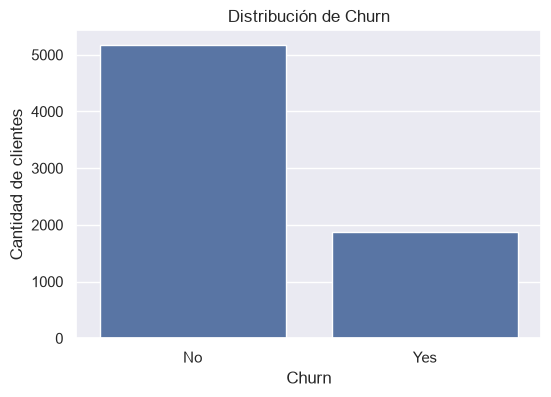

In [ ]:
# Gráfico de distribución de Churn
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Distribución de Churn")
plt.xlabel("Churn")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

La variable (`Churn`) presenta un desbalance entre sus dos clases. La cantidad de clientes que permanecen en el servicio (`No`) es considerablemente mayor que la cantidad de clientes que abandonan (`Yes`).

Este desbalance es relevante para el desarrollo del modelo, ya que un modelo podría obtener un Accuracy elevado simplemente por predecir con mayor frecuencia la clase mayoritaria. Por este motivo, más adelante será necesario analizar otras métricas además del Accuracy, como Precision, Recall y F1-Score.

### 1.8 Relación entre Churn y tipo de contrato

Una de las variables que puede resultar relevante para el problema de negocio es el tipo de contrato del cliente. Analizamos su relación con `Churn` para observar si existen diferencias en la distribución del abandono entre los distintos tipos de contrato.

Esta visualización permite identificar patrones en los datos, aunque las diferencias observadas no deben interpretarse como relaciones causales.

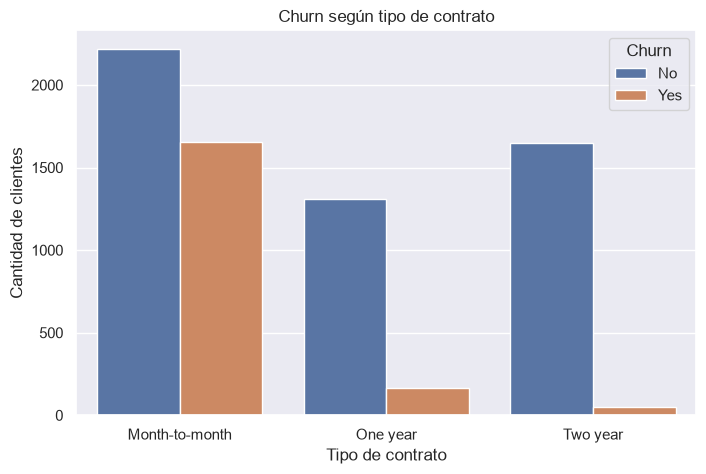

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

La distribución de `Churn` varía considerablemente según el tipo de contrato. Se observa una mayor cantidad de clientes que abandonan el servicio entre aquellos que poseen contratos `Month-to-month`, mientras que el abandono es mucho menos frecuente entre los clientes con contratos de uno o dos años.

Esto sugiere que el tipo de contrato podría ser una variable relevante para predecir `Churn`. Sin embargo, al tratarse de un análisis exploratorio, esta observación representa una asociación entre las variables y no permite establecer una relación causal.

### 1.9 Relación entre cargos mensuales y Churn

También analizamos la distribución de `MonthlyCharges` según la variable objetivo. El objetivo es observar si existen diferencias en los cargos mensuales entre los clientes que abandonan el servicio y aquellos que permanecen.

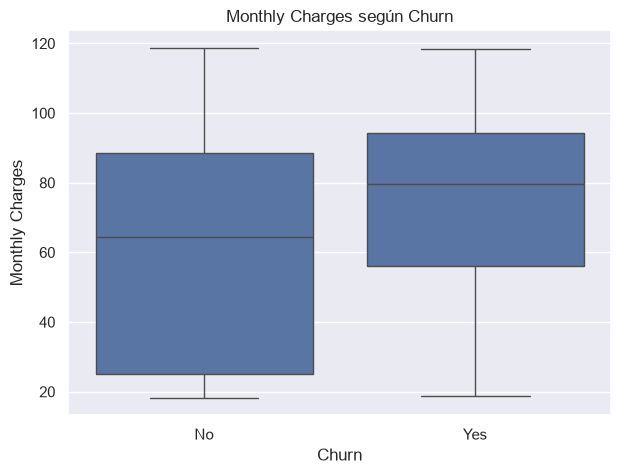

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges según Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

### Interpretación

El boxplot muestra diferencias en la distribución de `MonthlyCharges` entre ambas clases de `Churn`. Los clientes que abandonan el servicio presentan, en general, cargos mensuales más elevados que aquellos que permanecen.

Esto indica que `MonthlyCharges` podría aportar información útil para la predicción de `Churn`, aunque esta visualización por sí sola no permite afirmar que un cargo mensual más elevado sea la causa del abandono.

### 1.10 Relación entre antigüedad y Churn

Finalmente, analizamos la relación entre la antigüedad del cliente (`tenure`) y `Churn`. La antigüedad puede ser una variable relevante para entender el comportamiento de abandono, ya que permite comparar la distribución de los clientes según el tiempo que llevan utilizando el servicio.

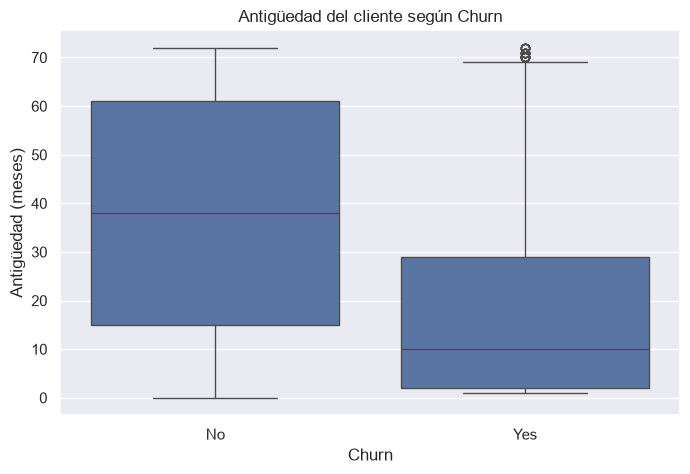

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Antigüedad del cliente según Churn")
plt.xlabel("Churn")
plt.ylabel("Antigüedad (meses)")

plt.show()

### Interpretación

Se observa una diferencia clara en la antigüedad de los clientes según `Churn`. Los clientes que permanecen en el servicio presentan una distribución de `tenure` más elevada y amplia, mientras que los clientes que abandonan se concentran principalmente en los primeros meses de permanencia.

Esto sugiere que la antigüedad del cliente puede ser una variable relevante para la predicción del abandono, ya que existe una diferencia observable en su distribución entre ambas clases.

### 1.11 Conclusiones del análisis exploratorio

El conjunto de datos está compuesto por 7.043 clientes y 21 variables. La mayoría de las variables son categóricas, mientras que `SeniorCitizen`, `tenure`, `MonthlyCharges` y `TotalCharges` son variables numéricas.

Durante la exploración se detectó una anomalía en `TotalCharges`, que originalmente era interpretada como una variable de tipo texto a pesar de representar una cantidad numérica. Al realizar su conversión a formato numérico, se identificaron 11 valores que no podían convertirse y que fueron tratados como valores faltantes.

La variable objetivo `Churn` presenta un desbalance entre sus clases: el 73,46% de los clientes no abandonó el servicio, mientras que el 26,54% sí lo hizo. Esta diferencia será importante al momento de entrenar y evaluar los modelos, ya que un modelo que simplemente predijera la clase mayoritaria podría obtener un Accuracy del 73,46% sin identificar correctamente a los clientes que abandonan.

Las visualizaciones también muestran diferencias entre los clientes que abandonan y los que permanecen. En particular, se observa una mayor concentración de casos de abandono entre los clientes con contratos `Month-to-month`, mayores cargos mensuales y menor antigüedad. Estos patrones sugieren que estas variables podrían aportar información relevante para la predicción de `Churn`, aunque el análisis exploratorio por sí solo no permite establecer relaciones causales.



# 2.   Preprocesamiento y prevención de Data Leakage
## 2.1 Valores faltantes
  Ya revisamos el tipo de todas las columnas y convertimos la columna TotalCharges de tipo texto a numérica. Ahora bien, encontramos que esta además tiene 11 celdas con valores faltantes, también conocidos como Nans. A estos Nans hay que manejarlos correctamente y para eso existen varias herramientas que podemos utilizar para trabajar el problema lo mejor posible. Sin embargo antes de apresurarse a manejarlos con la primer herramienta que recordemos hay que entender el problema y analizar el sesgo que puede generar cada herramienta.  



In [ ]:
Nans = df.loc[total_charges_numeric.isna()]
Nans

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### Comparación de las 11 filas con el resto de la muestra

Ahora, para comparar las características de estos 11 clientes con el resto de la población, podemos iterar a través de las columnas y mostrar estadísticas descriptivas o conteos de valores para cada una en ambos DataFrames (`Nans` y `df`).

In [ ]:
print('--- Comparación de la PROPORCIÓN DIRECTA entre Nans y el DataFrame completo (df) ---')
print('  (Conteo de categoría en Nans) / (Conteo de categoría en df)  ')

# Identificar todas las columnas (excluyendo 'customerID' de la comparación de patrones)
columnas = df.columns.tolist()
if 'customerID' in columnas:
    columnas.remove('customerID')

print('\n### Proporción de las 11 muestras por columna ###')
for col in columnas:
    print(f'\n---- Columna: {col} ----')
    muestra11 = Nans[col].value_counts(dropna=False)
    muestraTotal = df[col].value_counts(dropna=False)

    # Alineamos los índices para asegurar que la división se haga correctamente
    # y maneje casos donde una categoría pueda no existir en uno de los DataFrames
    proporcion = muestra11.div(muestraTotal, fill_value=0) # fill_value=0 para evitar NaN en el cociente si muestraTotal es 0

    print(f'\nPorcentaje (muestra11 / muestraTotal) para "{col}":')
    print((proporcion * 100).map(lambda x: f'{x:.2f}%')) # Multiplicar por 100 y formatear como porcentaje con 2 decimales


# Un NaN en el ratio indica que el denominador (df_counts) era cero para esa categoría,
# lo cual no debería ocurrir si Nans es un subconjunto de df.

--- Comparación de la PROPORCIÓN DIRECTA entre Nans y el DataFrame completo (df) ---
  (Conteo de categoría en Nans) / (Conteo de categoría en df)  

### Proporción de las 11 muestras por columna ###

---- Columna: gender ----

Porcentaje (muestra11 / muestraTotal) para "gender":
gender
Male      0.17%
Female    0.14%
Name: count, dtype: str

---- Columna: SeniorCitizen ----

Porcentaje (muestra11 / muestraTotal) para "SeniorCitizen":
SeniorCitizen
0    0.19%
1    0.00%
Name: count, dtype: str

---- Columna: Partner ----

Porcentaje (muestra11 / muestraTotal) para "Partner":
Partner
No     0.05%
Yes    0.26%
Name: count, dtype: str

---- Columna: Dependents ----

Porcentaje (muestra11 / muestraTotal) para "Dependents":
Dependents
No     0.00%
Yes    0.52%
Name: count, dtype: str

---- Columna: tenure ----

Porcentaje (muestra11 / muestraTotal) para "tenure":
tenure
0     100.00%
1       0.00%
2       0.00%
3       0.00%
4       0.00%
       ...   
68      0.00%
69      0.00%
70      0.

A partir de este análisis vemos que las filas no son significativas en la mayoría de columnas. De hecho, en ellas representan siempre menos del 1% con respecto a la muestra total, salvo en `tenure`.

Las 11 filas con `NaN` en `TotalCharges` tienen `tenure = 0` y representan el 100% de los clientes con `tenure = 0` en la muestra total. Esto es completamente entendible ya que, al tener 0 meses de antigüedad, son clientes nuevos. Sus `MonthlyCharges` existen porque ya contrataron servicios con un costo mensual, pero sus `TotalCharges` son `NaN` porque aún no han acumulado ningún cargo total. Por lo tanto, se concluye que el valor de `TotalCharges` para estos clientes debería imputarse como `0` y no como Nan.

Considerando esto, la imputación de `TotalCharges` a `0` para las 11 filas con `tenure = 0` es un dato exacto, no una aproximación. No hay que eliminarlas. Es un valor real porque son clientes nuevos que no han acumulado cargos. Respecto al sesgo, creemos que no lo genera, ya que estamos corrigiendo el dato entendiendo su contexto real.

### Imputación de TotalCharges

Siguiendo la conclusión del análisis anterior, imputamos los 11 valores faltantes de
`TotalCharges` con `0`.

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Valores faltantes restantes:", df.isnull().sum().sum())

Valores faltantes restantes: 0


## 2.2 Redundancia estructural en variables categóricas
Al analizar las variables categóricas con mayor detalle, observamos que varias de ellas
presentan una tercera categoría que parece depender funcionalmente de otra columna:

- Las seis variables asociadas a servicios de internet (`OnlineSecurity`, `OnlineBackup`,
  `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) presentan el valor
  `"No internet service"`.
- `MultipleLines` presenta el valor `"No phone service"`.

Creemos que estas categorías son redundantes, ya que la información que
dan ("el cliente no tiene internet" / "el cliente no tiene servicio telefónico")
ya está contenida en `InternetService` y `PhoneService` respectivamente.

In [ ]:
servicios_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
# Colapso de categorías redundantes
df[servicios_internet] = df[servicios_internet].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# Verificamos el resultado
print("Categorías tras el colapso:\n")
for col in servicios_internet + ["MultipleLines"]:
    print(f"{col:20s} -> {sorted(df[col].unique())}")

Categorías tras el colapso:

OnlineSecurity       -> ['No', 'Yes']
OnlineBackup         -> ['No', 'Yes']
DeviceProtection     -> ['No', 'Yes']
TechSupport          -> ['No', 'Yes']
StreamingTV          -> ['No', 'Yes']
StreamingMovies      -> ['No', 'Yes']
MultipleLines        -> ['No', 'Yes']


## 2.3 Eliminación de customerID
`customerID` es un identificador arbitrario con 7043 valores únicos sobre 7043 filas, o sea que
no representa ningún atributo del cliente, por lo que no aporta información generalizable.
Incluirlo sería además perjudicial, ya que un modelo con suficiente capacidad podría
memorizar clientes individuales en lugar de aprender patrones, caso claro de overfitting.

Al no observar el target,
esta decisión es segura antes de la partición.

In [ ]:
print("Valores únicos en customerID:", df["customerID"].nunique(), "sobre", len(df), "filas")

df = df.drop(columns=["customerID"])

print("Dimensiones tras la eliminación:", df.shape)

Valores únicos en customerID: 7043 sobre 7043 filas
Dimensiones tras la eliminación: (7043, 20)


## 2.4 Conversión de la variable objetivo
Convertimos `Churn` de `"Yes"`/`"No"` a `1`/`0`. Asignamos el `1` a la clase `"Yes"`
(abandono) porque es la clase de interés del problema de negocio. Básicamente es la que queremos
detectar, y es la que las métricas de Precision y Recall tomarán como clase positiva en
el próximo análisis.

In [ ]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print(df["Churn"].value_counts())
print(f"\nProporción de la clase positiva: {df['Churn'].mean():.2%}")

Churn
0    5174
1    1869
Name: count, dtype: int64

Proporción de la clase positiva: 26.54%


## 2.5 Train/Test Split


En general, el escalado y la imputación deben hacerse después de la partición. Supongamos que para completar los Nans utilizamos la mediana de toda la muestra,
estaríamos incluyendo en la imputación información de las filas que luego se separan como
testeo. A esto se lo conoce como data leakage y hace que el modelo termine viendo, aunque sea
indirectamente, información del test, así que cuando lo evaluamos las métricas nos dan
mejor de lo que realmente son. Con el escalado pasaría lo mismo, ya que la media y el
desvío saldrían de todo el dataset y no solamente del train.

En nuestro caso el escalado no se aplica, por lo que no lo incluimos. La imputación, en
cambio, la realizamos antes del split. Esto es válido porque el valor imputado no se estima
a partir de la muestra, sino que se deduce de comprender el problema, (`tenure = 0`). Estamos completando la columna con un dato real
y exacto, no con una aproximación.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=7
)

print(f"Train: {X_train.shape[0]} filas | Churn = {y_train.mean():.2%}")
print(f"Test:  {X_test.shape[0]} filas | Churn = {y_test.mean():.2%}")

Train: 5634 filas | Churn = 26.54%
Test:  1409 filas | Churn = 26.54%


## 2.6 Codificación de variables categóricas

Los modelos de sklearn no trabajan con texto, así que hay que pasar las categóricas a
numéricas con One-Hot Encoding, que crea una columna por cada categoría.

Usamos `drop="if_binary"`, que en las variables de dos categorías genera una sola columna en
lugar de dos. Esto tiene sentido porque, al ser una el complemento de la otra, la segunda no
aportaría información nueva. En las variables con más de dos categorías el One-Hot se aplica
completo. Después del colapso que hicimos en 2.2 la mayoría quedó binaria, así que esto nos
ahorra bastantes columnas.

Las numéricas pasan sin transformar por lo que explicamos en 2.7.

Organizamos la preparación de los datos (como convertir texto en números con ColumnTransformer) dentro de un Pipeline. Esto garantiza que las reglas de preparación se aprendan solo con los datos de entrenamiento. Así, evitamos que el modelo 'vea' los datos de prueba antes de tiempo y se reajuste correctamente en cada validación.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

col_categoricas = X_train.select_dtypes(include="object").columns.tolist()
col_numericas   = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

preprocesador = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), col_categoricas),
        ("numericas", "passthrough", col_numericas),
    ]
)

print("Categóricas:", col_categoricas)

Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Ajustamos solo sobre train para ver cómo quedan las columnas
preprocesador.fit(X_train)
nombres = preprocesador.get_feature_names_out()

print(f"Columnas antes: {X_train.shape[1]}  ->  después: {len(nombres)}\n")
for n in nombres:
    print("  -", n)

Columnas antes: 19  ->  después: 26

  - categoricas__gender_Male
  - categoricas__Partner_Yes
  - categoricas__Dependents_Yes
  - categoricas__PhoneService_Yes
  - categoricas__MultipleLines_Yes
  - categoricas__InternetService_DSL
  - categoricas__InternetService_Fiber optic
  - categoricas__InternetService_No
  - categoricas__OnlineSecurity_Yes
  - categoricas__OnlineBackup_Yes
  - categoricas__DeviceProtection_Yes
  - categoricas__TechSupport_Yes
  - categoricas__StreamingTV_Yes
  - categoricas__StreamingMovies_Yes
  - categoricas__Contract_Month-to-month
  - categoricas__Contract_One year
  - categoricas__Contract_Two year
  - categoricas__PaperlessBilling_Yes
  - categoricas__PaymentMethod_Bank transfer (automatic)
  - categoricas__PaymentMethod_Credit card (automatic)
  - categoricas__PaymentMethod_Electronic check
  - categoricas__PaymentMethod_Mailed check
  - numericas__SeniorCitizen
  - numericas__tenure
  - numericas__MonthlyCharges
  - numericas__TotalCharges


## 2.7 Feature Scaling

Las numéricas tienen rangos bastante distintos, `TotalCharges` va de 18.8 a 8684.8 mientras
que `tenure` va de 0 a 72. Aún así decidimos no escalarlas, porque el modelo que vamos a usar es
árbol de decisión.

Los árboles parten el espacio con cortes del tipo `variable <= umbral`, y como el escalado no
cambia el orden de los valores, un corte en `TotalCharges <= 1500` pasaría a ser
`TotalCharges_escalado <= -0.35`, o sea la misma división de las mismas filas. El árbol
quedaría idéntico y lo único que lograríamos es perder interpretabilidad, ya que los umbrales
del gráfico quedarían en unidades sin sentido de negocio.

El escalado sí haría falta con modelos que usan distancias como KNN o gradientes como regresión
logística, donde `TotalCharges` dominaría sobre `tenure` por su magnitud y no por ser
más relevante. Si lo incorporáramos más adelante iría dentro del `Pipeline`, para que el
`fit` se haga solo sobre train.

## 3. Estrategia de Validación

### 3.1 K-Fold Cross-Validation

Para evaluar el comportamiento del modelo utilizaremos Cross-Validation sobre el conjunto de entrenamiento. La consigna nos pide utilizar K-Fold Cross-Validation con K=5.

La idea de K-Fold consiste en dividir el conjunto de entrenamiento en 5 partes o "folds". En cada iteración, el modelo se entrena utilizando 4 de estas partes y se valida utilizando la restante. Este proceso se repite hasta que cada fold haya sido utilizado una vez como conjunto de validación.

De esta manera obtenemos 5 resultados de validación en lugar de depender de una única partición de entrenamiento y validación.

### 3.2 K-Fold vs Holdout

Una alternativa más simple sería utilizar una partición de Holdout, separando una parte del conjunto de entrenamiento para validación y utilizando el resto para entrenar el modelo. El principal problema de este enfoque es que el resultado de la evaluación puede depender demasiado de una única partición de los datos.

K-Fold Cross-Validation permite utilizar distintas particiones del conjunto de entrenamiento para realizar la validación. En nuestro caso, con K=5, cada observación del conjunto de entrenamiento participa en la validación exactamente una vez y en el entrenamiento cuatro veces.

Esto permite obtener una evaluación más robusta del comportamiento del modelo y utilizar de manera más eficiente la información disponible en el conjunto de entrenamiento. Además, podemos observar los resultados obtenidos en los diferentes folds y calcular su promedio, reduciendo la dependencia de una única partición de los datos.

Es importante destacar que la Cross-Validation se realizará únicamente sobre el conjunto de entrenamiento. El conjunto de test se mantendrá separado y no será utilizado durante esta etapa, ya que debe guardarse para la evaluación final del modelo.

### 3.3 ¿Es conveniente utilizar Stratified K-Fold?

En este dataset resulta conveniente utilizar Stratified K-Fold en lugar de K-Fold tradicional. La variable objetivo `Churn` presenta un desbalance considerable: el 73,46% de los clientes pertenece a la clase `No`, mientras que solamente el 26,54% pertenece a la clase `Yes`.

Al utilizar Stratified K-Fold, cada uno de los 5 folds mantiene aproximadamente la misma proporción de clientes de cada clase que existe en el conjunto de entrenamiento completo. Esto es especialmente importante porque queremos evaluar correctamente la capacidad del modelo para identificar clientes que abandonan el servicio, que representan la clase minoritaria.

Con un K-Fold tradicional, una división aleatoria podría generar folds con proporciones de clases diferentes, haciendo que algunas validaciones sean menos representativas de la distribución real del conjunto de entrenamiento.

Por este motivo, utilizaremos Stratified K-Fold con K=5 para nuestra validación cruzada.

### 3.4 Implementación

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=7
)

Utilizamos `StratifiedKFold` con 5 folds. Activamos `shuffle=True` para aleatorizar la distribución de las observaciones antes de realizar las divisiones y fijamos `random_state=7` para poder reproducir los resultados.

### 3.5 Verificar la distribución de Churn en cada fold

In [ ]:
import numpy as np

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):

    y_val_fold = y_train.iloc[val_idx]

    porcentaje_churn = y_val_fold.mean() * 100

    print(
        f"Fold {fold}: "
        f"{porcentaje_churn:.2f}% Churn"
    )

Fold 1: 26.53% Churn
Fold 2: 26.53% Churn
Fold 3: 26.53% Churn
Fold 4: 26.53% Churn
Fold 5: 26.55% Churn


### 3.6 Cross-Validation del modelo

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

modelo_base = DecisionTreeClassifier(random_state=7)

pipeline = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", modelo_base)
])

In [ ]:
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    return_train_score=False
)

In [ ]:
cv_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1-Score": cv_results["test_f1"]
})

cv_scores

,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.719610,0.468864,0.428094,0.447552
1,2,0.737356,0.505495,0.461538,0.482517
2,3,0.728483,0.488818,0.511706,0.500000
3,4,0.709849,0.455696,0.481605,0.468293
4,5,0.731794,0.494881,0.484950,0.489865


### 3.7 Promedio de las métricas

In [ ]:
cv_summary = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Promedio": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],
    "Desvío estándar": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std()
    ]
})

cv_summary

,Métrica,Promedio,Desvío estándar
0,Accuracy,0.725418,0.009682
1,Precision,0.482751,0.018033
2,Recall,0.473579,0.027789
3,F1-Score,0.477645,0.018253


### 3.8 Interpretación de los resultados

La validación cruzada mediante Stratified K-Fold con K=5 produjo un Accuracy promedio de 72,54%, una Precision de 48,28%, un Recall de 47,36% y un F1-Score de 47,76%.

El Accuracy resulta particularmente relevante al compararlo con la distribución de la variable objetivo. Como el 73,46% de los clientes pertenece a la clase `No Churn`, un modelo que predijera siempre la clase mayoritaria alcanzaría un Accuracy de 73,46%. Por lo tanto, el Accuracy obtenido por nuestro modelo es incluso ligeramente inferior al que obtendría este modelo naive.

Por otro lado, las métricas centradas en la clase positiva muestran que el modelo identifica aproximadamente el 47% de los clientes que efectivamente abandonan el servicio (Recall), mientras que aproximadamente el 48% de las predicciones positivas son correctas (Precision). El F1-Score, de 47,76%, refleja este desempeño conjunto de Precision y Recall.

En cuanto a la variabilidad entre los folds, los desvíos estándar son bajos. El Accuracy presenta un desvío estándar de 0,97 puntos porcentuales, mientras que el Recall presenta una variabilidad algo mayor, de aproximadamente 2,78 puntos porcentuales. Esto indica que, aunque el rendimiento en la detección de Churn varía algo entre las distintas particiones, los resultados generales del modelo son relativamente estables.

En conclusión, la utilización de Stratified K-Fold nos permitió obtener una evaluación más robusta del modelo sobre distintas particiones del conjunto de entrenamiento, manteniendo además una proporción similar de las clases en cada fold.

### 3.9 Diagnóstico: ¿el árbol está sobreajustado?

Antes de dar por bueno el árbol usado en la Cross-Validation anterior, comparamos su desempeño sobre el propio conjunto de entrenamiento de cada fold contra su desempeño sobre el fold de validación, usando `return_train_score=True`.

In [ ]:
from sklearn.metrics import accuracy_score

cv_diagnostico = cross_validate(
    pipeline,
    X_train, y_train,
    cv=cv,
    scoring=["accuracy", "f1"],
    return_train_score=True
)

print(f"Accuracy -> train: {cv_diagnostico['train_accuracy'].mean():.2%} | validación: {cv_diagnostico['test_accuracy'].mean():.2%}")
print(f"F1-Score -> train: {cv_diagnostico['train_f1'].mean():.2%} | validación: {cv_diagnostico['test_f1'].mean():.2%}")

pipeline.fit(X_train, y_train)
print(f"\nProfundidad del árbol sin restricciones: {pipeline.named_steps['modelo'].get_depth()}")

# Lo evaluamos también sobre test, para poder compararlo más adelante con el modelo optimizado
accuracy_sin_podar = accuracy_score(y_test, pipeline.predict(X_test))
print(f"Accuracy sobre test:                    {accuracy_sin_podar:.4f}")
print(f"Accuracy del modelo naive:              {1 - y_test.mean():.4f}")

Accuracy -> train: 99.84% | validación: 72.54%
F1-Score -> train: 99.71% | validación: 47.76%

Profundidad del árbol sin restricciones: 24
Accuracy sobre test:                    0.7445
Accuracy del modelo naive:              0.7346


La brecha es enorme: el árbol sin restricciones memoriza el 99,84% de Accuracy y el 99,71% de F1-Score en entrenamiento, pero cae a 72,54% y 47,76% en validación. Como la profundidad no está limitada (llega a 24 niveles), el árbol arma hojas para casos muy específicos del train en lugar de aprender patrones generales.

Sobre el conjunto de test la Accuracy queda en 74,45%, apenas por encima del modelo naive que siempre predice la clase mayoritaria (73,46%). Conviene quedarse con el número de validación cruzada antes que con el de test, porque el primero promedia 5 particiones y el segundo depende de una sola: en validación el modelo directamente no le gana al naive. En cualquier caso, la distancia entre el 99,84% de train y el 72,54% de validación es la señal clara de sobreajuste.

El problema no es el algoritmo Decision Tree en sí, sino dejarlo crecer sin ningún control de complejidad. Para resolverlo hay que limitar la complejidad del árbol (`max_depth`, `min_samples_leaf`) y elegir esos límites de manera objetiva en lugar de a mano. Para eso usamos la misma estrategia de Stratified K-Fold ya definida, pero ahora para comparar combinaciones de hiperparámetros en lugar de estimar el error de un único modelo fijo.

### 3.10 Selección de hiperparámetros con GridSearchCV

Buscamos la combinación de `max_depth` y `min_samples_leaf` que maximice el F1-Score promedio en la misma Cross-Validation de 5 folds (`cv`) definida en 3.4. Usamos F1 y no Accuracy como criterio de selección porque, como vimos en la Sección 1, el 73,46% de los clientes no hace Churn: optimizar por Accuracy llevaría a la búsqueda a preferir árboles casi triviales, que se acercan a ese porcentaje sin discriminar realmente la clase minoritaria.

`GridSearchCV` entrena y valida cada combinación en los 5 folds y, al finalizar, reentrena automáticamente (`refit=True`, su valor por defecto) la mejor combinación sobre la totalidad de `X_train`. Ese reentrenamiento sobre todo el train es el que la consigna pide para el modelo final de la Sección 4.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "modelo__max_depth": [3, 4, 5, 6, 7, 8, 10, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 30, 50],
}

grid_search = GridSearchCV(
    Pipeline([
        ("preprocesamiento", preprocesador),
        ("modelo", DecisionTreeClassifier(random_state=7))
    ]),
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_params_tree = {
    key.replace("modelo__", ""): value
    for key, value in grid_search.best_params_.items()
}

print("Mejores hiperparámetros:", grid_search.best_params_)
print(f"Mejor F1-Score promedio en Cross-Validation: {grid_search.best_score_:.4f}")

Mejores hiperparámetros: {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
Mejor F1-Score promedio en Cross-Validation: 0.5651


El mejor resultado se obtiene con `max_depth=5` y `min_samples_leaf=50`, con un F1-Score promedio en Cross-Validation de 0,5651. Es una mejora considerable respecto del árbol sin restricciones de 3.6, que había obtenido un F1 promedio de apenas 0,4776 en validación (a pesar de su 0,9971 en train). Limitar la profundidad y exigir un mínimo de observaciones por hoja evita que el árbol arme reglas demasiado específicas, y logra un modelo que generaliza mejor aunque sacrifique parte de la capacidad de ajustarse perfectamente al conjunto de entrenamiento.

## 4. Modelo Base

### 4.1 Entrenamiento del modelo final

Como modelo final utilizamos el árbol con los hiperparámetros seleccionados en 3.10 (`max_depth=5`, `min_samples_leaf=50`), que `GridSearchCV` ya reentrenó automáticamente sobre la totalidad de `X_train` (`grid_search.best_estimator_`).

El conjunto de test se mantuvo separado durante todas las etapas anteriores, incluyendo la búsqueda de hiperparámetros, y será utilizado únicamente en esta instancia para obtener una evaluación final del modelo sobre datos que no fueron utilizados durante el entrenamiento, la validación cruzada ni la selección de hiperparámetros.

In [ ]:
# El mejor modelo de la búsqueda de hiperparámetros ya fue reentrenado
# sobre la totalidad de X_train (GridSearchCV usa refit=True por defecto)
pipeline = grid_search.best_estimator_
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

### 4.2 Predicciones sobre el conjunto de test

Una vez entrenado el modelo final, realizamos las predicciones sobre el conjunto de test. Este conjunto no fue utilizado para ajustar el preprocesamiento, entrenar el modelo ni realizar la validación cruzada.

Por este motivo, las predicciones obtenidas sobre `X_test` nos permiten realizar una evaluación final del desempeño del modelo sobre datos no utilizados previamente.

In [ ]:
y_pred = pipeline.predict(X_test)

### 4.3 Matriz de Confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[899, 136],
       [135, 239]])

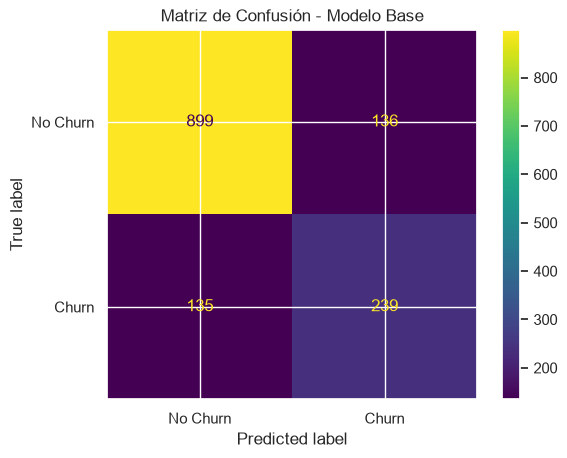

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Matriz de Confusión - Modelo Base")
plt.show()

### Interpretación de la matriz de confusión

La matriz de confusión permite analizar no solamente cuántas predicciones fueron correctas, sino también qué tipo de errores comete el modelo.

En nuestro problema:

- Verdadero Negativo (TN): cliente que no abandona y el modelo predice `No Churn`.
- Verdadero Positivo (TP): cliente que abandona y el modelo predice `Churn`.
- Falso Positivo (FP): cliente que no abandona, pero el modelo predice `Churn`.
- Falso Negativo (FN): cliente que abandona, pero el modelo predice `No Churn`.

Esta distinción será especialmente importante en la siguiente sección, donde analizaremos el impacto económico de estos errores para la empresa.

### 4.4 Métricas de evaluación

A continuación calculamos Accuracy, Precision, Recall y F1-Score sobre el conjunto de test.

Estas métricas permiten evaluar distintos aspectos del modelo. Debido al desbalance existente en la variable objetivo, no nos limitaremos al Accuracy, sino que también analizaremos específicamente el desempeño del modelo sobre la clase `Churn`.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.8077
Precision: 0.6373
Recall:    0.6390
F1-Score:  0.6382


### 4.5 Presentar las métricas como tabla

In [ ]:
test_summary = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Resultado": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

test_summary

,Métrica,Resultado
0,Accuracy,0.807665
1,Precision,0.637333
2,Recall,0.639037
3,F1-Score,0.638184


### 4.6 Comparación con un modelo naive

Para evaluar si el Accuracy del modelo base resulta realmente informativo, lo compararemos con un modelo naive que siempre predice la clase mayoritaria.

En nuestro dataset, la clase mayoritaria es `No Churn`, que representa el 73,46% de los clientes. Por lo tanto, un modelo que predijera `No Churn` para todos los clientes tendría un Accuracy esperado de 73,46%.

Esta comparación es importante porque permite determinar si nuestro modelo está logrando un desempeño superior al que obtendríamos sin utilizar las características de los clientes.

In [ ]:
# Modelo naive: siempre predice No Churn (0)
y_pred_naive = np.zeros(len(y_test), dtype=int)

accuracy_naive = accuracy_score(y_test, y_pred_naive)

print(f"Accuracy del modelo naive: {accuracy_naive:.4f}")

Accuracy del modelo naive: 0.7346


In [ ]:
comparison = pd.DataFrame({
    "Modelo": [
        "Decision Tree",
        "Modelo naive"
    ],
    "Accuracy": [
        accuracy,
        accuracy_naive
    ]
})

comparison

,Modelo,Accuracy
0,Decision Tree,0.807665
1,Modelo naive,0.734564


### 4.7 Interpretación de los resultados y comparación con el modelo naive

El modelo final (árbol con `max_depth=5` y `min_samples_leaf=50`) obtuvo un Accuracy de 80,77%, una Precision de 63,73%, un Recall de 63,90% y un F1-Score de 63,82% sobre el conjunto de test.

La matriz de confusión muestra 899 verdaderos negativos, 136 falsos positivos, 135 falsos negativos y 239 verdaderos positivos. El modelo identifica correctamente 239 de los 374 clientes que efectivamente abandonan el servicio, y comete una cantidad parecida de falsos positivos y falsos negativos.

En la Cross-Validation de 3.10 el F1 promedio había sido 0,5651 y sobre test da 0,6382. La diferencia a favor del test es esperable, porque el modelo final se entrena con todo el train y no con el 80% de cada fold. Igual conviene aclarar que ese 0,5651 es el mejor de las 48 combinaciones probadas, así que como estimación también está algo inflado.

Como el 73,46% de los clientes pertenece a la clase `No Churn`, un modelo naive que siempre predijera la clase mayoritaria tendría un Accuracy de 73,46%. El árbol sin restricciones de la Sección 3 apenas lo superaba en test (74,45%) y en validación cruzada quedaba por debajo (72,54%). Este modelo con hiperparámetros controlados alcanza 80,77% y lo supera con claridad.

Aun así, el Accuracy sigue sin ser la métrica más relevante para este problema: el Recall de 63,90% indica que el modelo todavía deja sin detectar a más de un tercio de los clientes que efectivamente abandonan. El desbalance de clases sigue afectando esta métrica en particular, y será el foco de la siguiente sección.

# 5. Análisis de Negocio e Impacto de las Métricas

Marketing usará las predicciones para ofrecer un descuento del 50% por 3 meses a los clientes
que el modelo marque como propensos a fugarse. Entrenamos un segundo modelo que ataque el
desbalanceo y después traducimos cada tipo de error a plata.

## 5.1 Segundo modelo: Oversampling

Random Oversampling replica ejemplos de la clase minoritaria hasta igualar ambas clases, para
que el árbol deje de tener el incentivo a ignorarla. Lo elegimos sobre SMOTE porque casi todas
nuestras variables son categóricas binarias y SMOTE interpola entre puntos, generando valores
intermedios que no tienen sentido en una columna de 0 y 1.

El resampleo va dentro del `Pipeline` de `imbalanced-learn` y no aplicado a mano sobre
`X_train`, de manera que se ejecuta solo en el `fit` y se saltea en el `predict`, lo que además permite
usarlo dentro de cross-validation sin que las copias se filtren entre folds.

Mantenemos los hiperparámetros seleccionados en 3.10 (`max_depth=5`, `min_samples_leaf=50`) también en este segundo modelo. Si dejáramos el árbol sin esa restricción, como en el primer intento de la Sección 3, el resampleo no serviría de mucho (overfitting).

,Métrica,Base,Oversampling
0,Accuracy,0.8077,0.7559
1,Precision,0.6373,0.5261
2,Recall,0.6390,0.8075
3,F1-Score,0.6382,0.6371


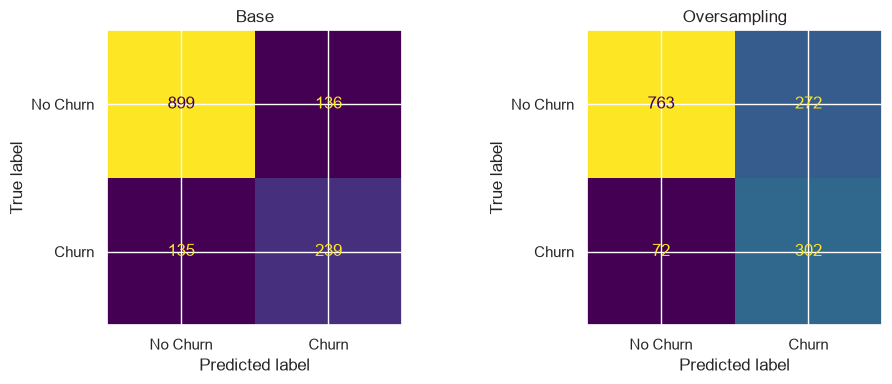

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone

pipeline_over = ImbPipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("resampleo",        RandomOverSampler(random_state=7)),
    ("modelo",           DecisionTreeClassifier(random_state=7, **best_params_tree))
])

pipeline_over.fit(X_train, y_train)
y_pred_over = pipeline_over.predict(X_test)
cm_over = confusion_matrix(y_test, y_pred_over)

display(pd.DataFrame({
    "Métrica":      ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Base":         [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                     recall_score(y_test, y_pred),   f1_score(y_test, y_pred)],
    "Oversampling": [accuracy_score(y_test, y_pred_over), precision_score(y_test, y_pred_over),
                     recall_score(y_test, y_pred_over),   f1_score(y_test, y_pred_over)],
}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matriz, titulo in zip(axes, [cm, cm_over], ["Base", "Oversampling"]):
    ConfusionMatrixDisplay(matriz, display_labels=["No Churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

El oversampling cambia el balance entre Precision y Recall de forma muy clara: el Recall sube de 63,90% a 80,75% (63 verdaderos positivos más, de 239 a 302), pero la Precision baja de 63,73% a 52,61% (136 falsos positivos más) y el Accuracy cae de 80,77% a 75,59%.

Lo llamativo es que el F1-Score queda prácticamente igual, 0,6382 el modelo base contra 0,6371 el de oversampling. En esta partición el resampleo no mejoró el balance general, solo movió el modelo hacia detectar más fugas a cambio de más falsas alarmas.

Antes de sacar conclusiones evaluamos que esto se sostenga en más de una partición del dataset, y si el modelo realmente está aprendiendo mejor o simplemente clasificando como Churn a más gente.

## 5.2 ¿La mejora es real?

Repetimos el entrenamiento con 5 particiones distintas y promediamos las métricas. Agregamos
undersampling para tener una segunda técnica con qué comparar.

In [ ]:
from sklearn.metrics import average_precision_score

def armar(seed, balanceo=None, podado=True):
    pasos = [("preprocesamiento", clone(preprocesador))]
    if balanceo == "over":
        pasos.append(("resampleo", RandomOverSampler(random_state=seed)))
    if balanceo == "under":
        pasos.append(("resampleo", RandomUnderSampler(random_state=seed)))
    parametros = best_params_tree if podado else {}
    pasos.append(("modelo", DecisionTreeClassifier(random_state=seed, **parametros)))
    return ImbPipeline(pasos) if balanceo else Pipeline(pasos)

configs = [("Sin podar",                None,    False),
           ("Sin podar + Oversampling", "over",  False),
           ("Podado (modelo base)",     None,    True),
           ("Podado + Oversampling",    "over",  True),
           ("Podado + Undersampling",   "under", True)]

resultados = {}
for nombre, bal, pod in configs:
    m = {"Accuracy": [], "Precision": [], "Recall": [], "F1": [], "AP": []}
    for s in range(5):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
        modelo = armar(s, bal, pod).fit(Xtr, ytr)
        pred = modelo.predict(Xte)
        prob = modelo.predict_proba(Xte)[:, 1]
        m["Accuracy"].append(accuracy_score(yte, pred));   m["Precision"].append(precision_score(yte, pred))
        m["Recall"].append(recall_score(yte, pred));       m["F1"].append(f1_score(yte, pred))
        m["AP"].append(average_precision_score(yte, prob))   # AP no depende del umbral
    resultados[nombre] = m

display(pd.DataFrame([{"Modelo": n, **{k: np.mean(v) for k, v in m.items()}}
                      for n, m in resultados.items()]).round(4))

def veces_que_gana(tecnica, base, metrica):
    return sum(a > b for a, b in zip(resultados[tecnica][metrica], resultados[base][metrica]))

print("El oversampling le gana al árbol correspondiente en:")
print(f"  árbol sin podar -> F1 en {veces_que_gana('Sin podar + Oversampling','Sin podar','F1')}/5 particiones")
print(f"  árbol podado    -> F1 en {veces_que_gana('Podado + Oversampling','Podado (modelo base)','F1')}/5 particiones")
print(f"  árbol podado    -> AP en {veces_que_gana('Podado + Oversampling','Podado (modelo base)','AP')}/5 particiones")

,Modelo,Accuracy,Precision,Recall,F1,AP
0,Sin podar,0.7296,0.4913,0.5091,0.4997,0.3822
1,Sin podar + Oversampling,0.7337,0.4986,0.4925,0.4953,0.3809
2,Podado (modelo base),0.7908,0.6120,0.5775,0.5936,0.6163
3,Podado + Oversampling,0.7343,0.5005,0.8059,0.6172,0.6120
4,Podado + Undersampling,0.7360,0.5039,0.7765,0.6097,0.5915


El oversampling le gana al árbol correspondiente en:
  árbol sin podar -> F1 en 1/5 particiones
  árbol podado    -> F1 en 5/5 particiones
  árbol podado    -> AP en 1/5 particiones


Cabe aclarar que estas 5 particiones son distintas de la que usamos en la Sección 4, así que los valores no coinciden exactamente con los de 5.1. Justamente por eso las miramos, para no depender de una sola partición.

La tabla nos mostró 2 cosas.

Por un lado el resampleo solo sirve si antes arreglamos el sobreajuste. Sobre el árbol sin podar, el oversampling deja el F1 en 0,4953 contra 0,4997 del árbol solo, y le gana en apenas 1 de 5 particiones (no cambia nada). Sobre el árbol podado sí sube el F1 de 0,5936 a 0,6172, ganando en las 5 de 5. Esto confirma lo que anticipamos en 5.1, vemos que conviene resolver el overfitting antes de atacar el desbalance, no al revés.

Por otro lado, agregamos la columna AP (Average Precision), que mide qué tan bien el modelo ordena a los clientes de más a menos riesgoso y no depende del umbral que usemos para decidir. Ahí el oversampling queda en 0,6120 contra 0,6163 del modelo base, y le gana en solo 1 de 5 particiones. Básicamente, el modelo con oversampling no distingue mejor a los clientes, ordena prácticamente igual.

Entonces, ¿por qué sube el F1? Porque al balancear las clases el árbol se vuelve más propenso a predecir Churn, lo que equivale a bajar el umbral de decisión. Sube el Recall, baja la Precision, y según la partición ese intercambio favorece o no al F1. Pero eso es mover el punto de corte, no aprender mejor. En 5.4 lo comprobamos moviendo el umbral directamente, sin tocar los datos.

Oversampling y Undersampling quedan muy parecidos en F1 (0,6172 y 0,6097). Seguimos el análisis económico con el de Oversampling, que es el que ya veníamos usando y que además aprovecha todas las filas en lugar de descartar observaciones de la clase mayoritaria.

## 5.3 Impacto económico de cada error

Para pasar de métricas a plata necesitamos algunos supuestos que el dataset no trae:

- Un cliente que se va representa 12 meses de facturación que dejamos de cobrar.
- El descuento se le paga a todos los clientes contactados, no solo a los falsos positivos.
- El descuento logra retener al cliente con probabilidad `P_RET`, que fijamos en 30%. Los clientes que contactamos y se van igual son el peor caso: pagamos el descuento y encima los perdemos.

El costo lo calculamos cliente por cliente usando su propio `MonthlyCharges` en lugar de un promedio general. Esto importa porque en el análisis exploratorio (1.9) vimos que los clientes que abandonan tienen cargos más altos que los que se quedan, así que usar un único promedio subestimaría lo que cuesta cada fuga.

In [ ]:
# Parámetros de referencia. Usamos la media de train para no mirar el conjunto de test.
cargo_prom = X_train["MonthlyCharges"].mean()
P_RET      = 0.30    # probabilidad de que el descuento retenga al cliente

print(f"Cargo mensual promedio (train):   ${cargo_prom:.2f}")
print(f"Descuento por cliente contactado: ${0.5 * cargo_prom * 3:.2f}")
print(f"Pérdida por cliente que se va:    ${cargo_prom * 12:.2f}")
print(f"Un Falso Negativo cuesta {(cargo_prom * 12) / (0.5 * cargo_prom * 3):.0f} veces más que un Falso Positivo.\n")

cargo = X_test["MonthlyCharges"].values   # el cargo real de cada cliente del test
real  = y_test.values

def costo_total(pred, nombre, p_ret=P_RET):
    tp = (real == 1) & (pred == 1)
    fp = (real == 0) & (pred == 1)
    fn = (real == 1) & (pred == 0)
    campania = (0.5 * cargo[tp | fp] * 3).sum()      # descuento a todos los contactados
    fugas_fn = (cargo[fn] * 12).sum()                # se van y no los detectamos
    fugas_tp = ((1 - p_ret) * cargo[tp] * 12).sum()  # los contactamos y se van igual
    return {"Modelo": nombre, "Contactados": int((tp | fp).sum()),
            "FP": int(fp.sum()), "FN": int(fn.sum()),
            "Costo campaña": campania, "Fugas no detectadas": fugas_fn,
            "Fugas pese al descuento": fugas_tp,
            "Costo total": campania + fugas_fn + fugas_tp}

sin_accion = np.zeros(len(real), dtype=int)

display(pd.DataFrame([costo_total(y_pred, "Base"),
                      costo_total(y_pred_over, "Oversampling"),
                      costo_total(sin_accion, "No hacer nada")]).round(0))

# Sensibilidad. Redondeamos solo las columnas de plata para no romper la de probabilidad.
tabla_sensibilidad = pd.DataFrame([
    {"P(retención)":  p,
     "Base":          costo_total(y_pred,      "-", p)["Costo total"],
     "Oversampling":  costo_total(y_pred_over, "-", p)["Costo total"],
     "No hacer nada": costo_total(sin_accion,  "-", p)["Costo total"]}
    for p in [0.0, 0.2, 0.3, 0.5, 1.0]])

display(tabla_sensibilidad.round({"Base": 0, "Oversampling": 0, "No hacer nada": 0}))

# ¿A partir de qué nivel de retención conviene cada opción? Lo buscamos probando valores.
grilla = np.arange(0.0, 1.001, 0.001)
costo_base = np.array([costo_total(y_pred,      "-", p)["Costo total"] for p in grilla])
costo_over = np.array([costo_total(y_pred_over, "-", p)["Costo total"] for p in grilla])
costo_nada = costo_total(sin_accion, "-")["Costo total"]

print(f"Retención mínima para que convenga hacer la campaña:")
print(f"  Base:         {grilla[costo_base < costo_nada][0]:.1%}")
print(f"  Oversampling: {grilla[costo_over < costo_nada][0]:.1%}")
print(f"\nEl Oversampling pasa a ser más barato que el Base a partir de una retención de "
      f"{grilla[costo_over < costo_base][0]:.1%}.")

Cargo mensual promedio (train):   $64.58
Descuento por cliente contactado: $96.87
Pérdida por cliente que se va:    $774.99
Un Falso Negativo cuesta 8 veces más que un Falso Positivo.



,Modelo,Contactados,FP,FN,Costo campaña,Fugas no detectadas,Fugas pese al descuento,Costo total
0,Base,375,136,135,42220.0,116891.0,154146.0,313258.0
1,Oversampling,574,272,72,64027.0,59836.0,194085.0,317948.0
2,No hacer nada,0,0,374,0.0,337100.0,0.0,337100.0


,P(retención),Base,Oversampling,No hacer nada
0,0.0,379321.0,401127.0,337100.0
1,0.2,335279.0,345674.0,337100.0
2,0.3,313258.0,317948.0,337100.0
3,0.5,269216.0,262495.0,337100.0
4,1.0,159112.0,123862.0,337100.0


Retención mínima para que convenga hacer la campaña:
  Base:         19.2%
  Oversampling: 23.1%

El Oversampling pasa a ser más barato que el Base a partir de una retención de 38.3%.


### Respuestas

1. Falso Positivo. Le damos el descuento a un cliente que se iba a quedar igual. Resignamos la mitad de su facturación durante 3 meses, unos \$97. No lo perdemos, solo perdemos margen.

2. Falso Negativo. El cliente se va y nunca lo contactamos. Perdemos toda su facturación futura, unos \$775 con el supuesto de 12 meses. Es 8 veces más caro que un falso positivo, y encima es una cuenta conservadora porque no incluye lo que cuesta conseguir un cliente nuevo que lo reemplace.

Esa diferencia de 8 a 1 no alcanza igual para elegir un modelo, porque todo depende de qué tan bien funcione el descuento. Con una retención del 30%, el modelo Base sale más barato que el de Oversampling (\$313.258 contra \$317.948). Vemos que contacta a 375 clientes en lugar de 574, así que gasta bastante menos en descuentos innecesarios, y eso pesa más que los falsos negativos de más que deja pasar. Los dos igual le ganan a no hacer nada (\$337.100).

La relación se da vuelta si el descuento funciona mejor. A partir de una retención del 38,3% el modelo de Oversampling pasa a ser el más barato, porque ahí el valor de las fugas que evita empieza a superar el costo de los falsos positivos extra. Y para que la campaña tenga sentido frente a no hacer nada, el descuento tiene que retener a más del 19,2% de los contactados con el modelo Base, o más del 23,1% con el de Oversampling.

3. ¿Precision o Recall? Depende de cuánto cueste el descuento.

- Si el descuento es caro, conviene maximizar Precision. Con el modelo Base contactamos a 375 clientes y 239 se iban de verdad, así que casi dos de cada tres contactos aciertan y se gasta poco en gente que se quedaba igual.
- Si el descuento es casi gratis, conviene maximizar Recall. El único error caro pasa a ser el falso negativo: el modelo Base deja ir sin intentar nada a 135 clientes, y con Oversampling esa cifra baja a 72.

En resumen, la métrica a optimizar no la define el modelo sino la relación entre lo que cuesta el descuento y lo que vale el cliente.

## 5.4 El umbral como palanca

En 5.2 vimos que el oversampling no ordena mejor a los clientes, solo hace que el modelo prediga Churn más seguido. Eso mismo se puede conseguir sin tocar los datos, moviendo el umbral de decisión. Lo que se hace es que en lugar de predecir Churn cuando la probabilidad supera 0,5, elegimos otro corte.

El umbral como sabemos es una decisión del modelo, así que no lo podemos elegir mirando el test (usaríamos dos veces el mismo conjunto y las métricas quedarían infladas). Lo elegimos con la misma Cross-Validation de 5 folds sobre train que veníamos usando, y recién después lo aplicamos al test.

También calculamos el umbral que sale directamente del negocio. Contactar a un cliente conviene si lo que esperamos ahorrar supera lo que cuesta el descuento, o sea si `probabilidad × P_RET × pérdida > descuento`. Despejando:

umbral = descuento / (P_RET × pérdida)

In [ ]:
from sklearn.model_selection import cross_val_predict

# Probabilidades de validación: cada cliente del train es predicho por un modelo que no lo vio
proba_cv = cross_val_predict(clone(pipeline), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales      = np.arange(0.05, 0.96, 0.01)
f1_por_umbral = [f1_score(y_train, (proba_cv > u).astype(int)) for u in umbrales]
umbral_cv     = umbrales[int(np.argmax(f1_por_umbral))]

umbral_negocio = (0.5 * cargo_prom * 3) / (P_RET * cargo_prom * 12)

print(f"Umbral que maximiza F1 en Cross-Validation (train): {umbral_cv:.2f}")
print(f"Umbral que sale del modelo de costos:               {umbral_negocio:.2f}\n")

proba_test = pipeline.predict_proba(X_test)[:, 1]

filas_umbral = []
for u in sorted({0.30, round(umbral_cv, 2), round(umbral_negocio, 2), 0.50, 0.70}):
    pred_u = (proba_test > u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_u).ravel()
    filas_umbral.append({"Umbral": u, "Contactados": tp + fp, "FP": fp, "FN": fn,
                         "Precision": tp / (tp + fp), "Recall": tp / (tp + fn),
                         "F1": f1_score(y_test, pred_u),
                         "Costo total": costo_total(pred_u, "-")["Costo total"]})

display(pd.DataFrame(filas_umbral).round(3))

print(f"F1 sobre test del modelo Base con umbral 0,50: {f1_score(y_test, y_pred):.4f}")
print(f"F1 sobre test con el umbral elegido en CV:     {f1_score(y_test, (proba_test > umbral_cv).astype(int)):.4f}")
print(f"F1 sobre test del modelo con Oversampling:     {f1_score(y_test, y_pred_over):.4f}")

Umbral que maximiza F1 en Cross-Validation (train): 0.27
Umbral que sale del modelo de costos:               0.42



,Umbral,Contactados,FP,FN,Precision,Recall,F1,Costo total
0,0.27,574,268,68,0.533,0.818,0.646,317764.125
1,0.30,561,257,70,0.542,0.813,0.650,316506.135
2,0.42,375,136,135,0.637,0.639,0.638,313258.125
3,0.50,375,136,135,0.637,0.639,0.638,313258.125
4,0.70,152,38,260,0.750,0.305,0.433,321713.325


F1 sobre test del modelo Base con umbral 0,50: 0.6382
F1 sobre test con el umbral elegido en CV:     0.6456
F1 sobre test del modelo con Oversampling:     0.6371


El resultado confirma lo de 5.2. Bajando el umbral de 0,50 a 0,27 el mismo modelo Base pasa de un F1 de 0,6382 a 0,6456, que es mejor que el 0,6371 del modelo con oversampling. Nunca duplicamos filas ni tiramos datos, solo cambiamos el punto de corte.

Esto no significa que el oversampling esté mal, sino que en este caso no aportó nada que el umbral no consiguiera solo. Sirve saberlo porque mover el umbral es más barato, más rápido, y sobre todo permite elegir el punto de corte con un criterio de negocio en vez de aceptar el 0,5 por defecto.

Con nuestros supuestos, el umbral que sale de los costos es 0,42. En la tabla se ve que da exactamente el mismo resultado que 0,50, porque el árbol no produce ninguna probabilidad entre esos dos valores y ningún cliente cambia de lado. Ese punto es también el de menor costo total (\$313.258) (el umbral que maximiza el F1 (0,27) contacta a mucha más gente y termina saliendo \$4.500 más caro).

# Parte II: Reformulando el Problema

## Planteamiento del nuevo problema

Para esta segunda parte del trabajo abandonamos la predicción de `Churn` y planteamos un problema predictivo diferente utilizando el mismo conjunto de datos.

Nuestro nuevo objetivo será predecir si un cliente pertenece al grupo de clientes con cargos mensuales altos.

Para construir este nuevo problema utilizaremos la variable numérica `MonthlyCharges` como base del nuevo target. Dividiremos a los clientes en dos grupos utilizando la mediana de `MonthlyCharges` como punto de corte:

- `0`: cliente con `MonthlyCharges` menor a la mediana.
- `1`: cliente con `MonthlyCharges` mayor o igual a la mediana.

Elegimos la mediana como punto de corte porque permite dividir la muestra en dos grupos de tamaños similares, evitando generar un nuevo problema de desbalance de clases. Además, el corte no depende de un valor elegido arbitrariamente, sino de la distribución observada en el propio dataset.

La pregunta predictiva que buscamos responder es:

> ¿Podemos predecir si un cliente tendrá cargos mensuales altos utilizando sus características y los servicios que tiene contratados?

In [ ]:
# Variables predictoras
X_nuevo = df.drop(
    columns=[
        "MonthlyCharges",
        "Churn"
    ]
)

# Variable original que utilizaremos para construir el nuevo target
monthly_charges = df["MonthlyCharges"]

# Train/Test Split
X_train_nuevo, X_test_nuevo, monthly_train, monthly_test = train_test_split(
    X_nuevo,
    monthly_charges,
    test_size=0.2,
    random_state=7
)

print("Train:", X_train_nuevo.shape)
print("Test:", X_test_nuevo.shape)

Train: (5634, 18)
Test: (1409, 18)


In [ ]:
mediana_monthly = monthly_train.median()

print(f"Mediana de MonthlyCharges calculada sobre Train: ${mediana_monthly:.2f}")

Mediana de MonthlyCharges calculada sobre Train: $70.40


In [ ]:
y_train_nuevo = (
    monthly_train >= mediana_monthly
).astype(int)

y_test_nuevo = (
    monthly_test >= mediana_monthly
).astype(int)

In [ ]:
print("Distribución del target en Train:")
print(y_train_nuevo.value_counts(normalize=True) * 100)

print("\nDistribución del target en Test:")
print(y_test_nuevo.value_counts(normalize=True) * 100)

Distribución del target en Train:
MonthlyCharges
1    50.035499
0    49.964501
Name: proportion, dtype: float64

Distribución del target en Test:
MonthlyCharges
0    50.603265
1    49.396735
Name: proportion, dtype: float64


### Interpretación

La mediana de `MonthlyCharges` calculada exclusivamente sobre el conjunto de entrenamiento parte la muestra casi exactamente por la mitad, 50,04% de los clientes queda en la clase de cargos altos y 49,96% en la de cargos bajos.

En el conjunto de test la distribución también queda equilibrada, con un 50,60% de clientes en la clase de cargos bajos y un 49,40% en la de cargos altos.

Esta distribución resulta adecuada para el problema de clasificación planteado, ya que ninguna de las clases es claramente mayoritaria. Además, al calcular el punto de corte únicamente utilizando Train y aplicar ese mismo valor a Test, evitamos utilizar información del conjunto de test para definir el target.

### Preprocesamiento de las variables

Al igual que en la primera parte del trabajo, las variables categóricas deben ser transformadas para poder ser utilizadas por el modelo. Utilizaremos One-Hot Encoding para representar las categorías como variables binarias.

Las variables numéricas se mantendrán en su escala original, ya que utilizaremos un árbol de decisión y este modelo no requiere escalado de las variables numéricas.

El preprocesamiento se incorpora dentro de un Pipeline para asegurar que cualquier transformación sea ajustada únicamente utilizando los datos de entrenamiento.

In [ ]:
# Identificamos las variables categóricas y numéricas
col_categoricas_nuevo = X_train_nuevo.select_dtypes(
    include="object"
).columns.tolist()

col_numericas_nuevo = X_train_nuevo.select_dtypes(
    include=np.number
).columns.tolist()

print("Variables categóricas:")
print(col_categoricas_nuevo)

print("\nVariables numéricas:")
print(col_numericas_nuevo)

Variables categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Variables numéricas:
['SeniorCitizen', 'tenure', 'TotalCharges']


In [ ]:
preprocesador_nuevo = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                drop="if_binary",
                handle_unknown="ignore"
            ),
            col_categoricas_nuevo
        ),
        (
            "numericas",
            "passthrough",
            col_numericas_nuevo
        )
    ]
)

El `OneHotEncoder` utiliza `handle_unknown="ignore"` para evitar problemas si durante la evaluación aparece alguna categoría que no haya estado presente en el conjunto utilizado para ajustar el encoder.

Las variables numéricas se mantienen sin transformar mediante `passthrough`, dado que los árboles de decisión no requieren que las variables estén escaladas.

### Modelo Out-of-the-Box

Para resolver el nuevo problema utilizaremos un árbol de decisión con sus parámetros por defecto, manteniendo únicamente `random_state=7` para garantizar reproducibilidad.

No realizaremos optimización de hiperparámetros ni técnicas de balanceo en esta etapa, ya que el objetivo es evaluar el desempeño de un modelo simple sobre el nuevo problema planteado.

In [ ]:
modelo_nuevo = Pipeline([
    ("preprocesamiento", preprocesador_nuevo),
    ("modelo", DecisionTreeClassifier(random_state=7))
])

### Entrenamiento y predicción

Entrenamos el Pipeline utilizando exclusivamente el conjunto de entrenamiento. Luego realizamos las predicciones sobre el conjunto de test, que se mantuvo separado durante el entrenamiento.

In [ ]:
modelo_nuevo.fit(
    X_train_nuevo,
    y_train_nuevo
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['gender','SeniorCitizen','Partner',...,'PaperlessBilling','PaymentMethod', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By speci

In [ ]:
y_pred_nuevo = modelo_nuevo.predict(
    X_test_nuevo
)

In [ ]:
accuracy_nuevo = accuracy_score(
    y_test_nuevo,
    y_pred_nuevo
)

precision_nuevo = precision_score(
    y_test_nuevo,
    y_pred_nuevo
)

recall_nuevo = recall_score(
    y_test_nuevo,
    y_pred_nuevo
)

f1_nuevo = f1_score(
    y_test_nuevo,
    y_pred_nuevo
)

print(f"Accuracy:  {accuracy_nuevo:.4f}")
print(f"Precision: {precision_nuevo:.4f}")
print(f"Recall:    {recall_nuevo:.4f}")
print(f"F1-Score:  {f1_nuevo:.4f}")

Accuracy:  0.9808
Precision: 0.9799
Recall:    0.9813
F1-Score:  0.9806


In [ ]:
resultados_nuevo = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Resultado": [
        accuracy_nuevo,
        precision_nuevo,
        recall_nuevo,
        f1_nuevo
    ]
})

resultados_nuevo

,Métrica,Resultado
0,Accuracy,0.980837
1,Precision,0.979914
2,Recall,0.981322
3,F1-Score,0.980617


In [ ]:
cm_nuevo = confusion_matrix(
    y_test_nuevo,
    y_pred_nuevo
)

cm_nuevo

array([[699,  14],
       [ 13, 683]])

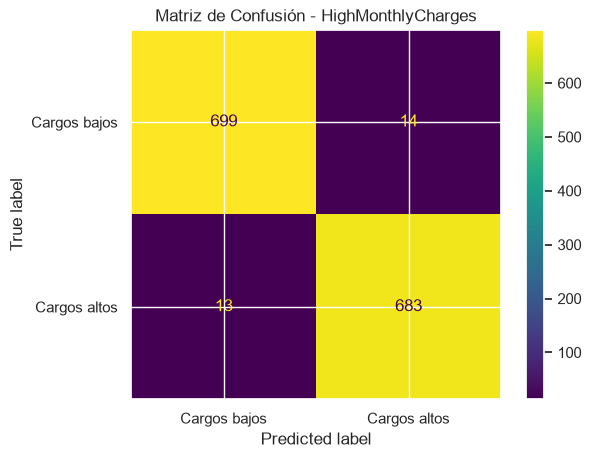

In [ ]:
disp_nuevo = ConfusionMatrixDisplay(
    confusion_matrix=cm_nuevo,
    display_labels=["Cargos bajos", "Cargos altos"]
)

disp_nuevo.plot()

plt.title("Matriz de Confusión - HighMonthlyCharges")
plt.show()

### Interpretación de los resultados

El árbol de decisión Out-of-the-Box obtuvo un Accuracy de 98,08%, una Precision de 97,99%, un Recall de 98,13% y un F1-Score de 98,06% sobre el conjunto de test. La matriz de confusión muestra 699 verdaderos negativos, 14 falsos positivos, 13 falsos negativos y 683 verdaderos positivos.

Es un resultado altísimo, sobre todo comparado con el 63,82% de F1 que conseguimos para `Churn`. Y es que desconfiamos al ser un modelo out-of-the-box, sin ajustar ningún hiperparámetro, que acierta el 98% en un problema con las clases balanceadas. Es una señal de que algo puede estar mal planteado. Antes de dar el resultado por bueno lo investigamos.

### ¿Por qué da tan bien? Revisión del target

Sospechamos de que el target no sea realmente algo "a predecir", sino algo que se puede reconstruir con una cuenta a partir de las columnas que le dejamos al modelo.

`MonthlyCharges` es lo que el cliente paga por mes y `TotalCharges` es lo que pagó en total. Si dividimos `TotalCharges` por `tenure` (la cantidad de meses que lleva), deberíamos recuperar aproximadamente el cargo mensual. Lo verificamos.

In [ ]:
# ¿TotalCharges / tenure reconstruye MonthlyCharges?
con_antiguedad = df[df["tenure"] > 0]
cociente = con_antiguedad["TotalCharges"] / con_antiguedad["tenure"]

print("TotalCharges / tenure comparado con MonthlyCharges:")
print(f"  correlación         : {cociente.corr(con_antiguedad['MonthlyCharges']):.4f}")
print(f"  diferencia promedio : ${(cociente - con_antiguedad['MonthlyCharges']).abs().mean():.2f}")

# Regla de una sola línea, sin entrenar ningún modelo
cociente_test = X_test_nuevo["TotalCharges"] / X_test_nuevo["tenure"].replace(0, 1)
regla_simple  = (cociente_test >= mediana_monthly).astype(int)

print(f"\nAccuracy de esa regla simple, sin modelo: {accuracy_score(y_test_nuevo, regla_simple):.4f}")
print(f"Accuracy del árbol que entrenamos:        {accuracy_nuevo:.4f}")

TotalCharges / tenure comparado con MonthlyCharges:
  correlación         : 0.9962
  diferencia promedio : $1.75

Accuracy de esa regla simple, sin modelo: 0.9759
Accuracy del árbol que entrenamos:        0.9808


Una división entre dos columnas, sin entrenar nada, acierta casi lo mismo que nuestro árbol. Eso quiere decir que el modelo no está prediciendo sino haciendo una cuenta.

Falta ver si el problema se arregla sacando esas columnas. Probamos entrenando el mismo árbol con distintos subconjuntos.

In [ ]:
def arbol_con(columnas):
    subconjunto = X_train_nuevo[columnas]
    categoricas = subconjunto.select_dtypes(include="object").columns.tolist()
    numericas   = subconjunto.select_dtypes(include=np.number).columns.tolist()
    modelo = Pipeline([
        ("preprocesamiento", ColumnTransformer([
            ("categoricas", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categoricas),
            ("numericas", "passthrough", numericas)])),
        ("modelo", DecisionTreeClassifier(random_state=7))
    ])
    modelo.fit(X_train_nuevo[columnas], y_train_nuevo)
    pred = modelo.predict(X_test_nuevo[columnas])
    return accuracy_score(y_test_nuevo, pred), f1_score(y_test_nuevo, pred)

todas    = list(X_train_nuevo.columns)
servicios = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
             "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

grupos = {
    "Todas las columnas":            todas,
    "Sin TotalCharges":              [c for c in todas if c != "TotalCharges"],
    "Sin TotalCharges ni tenure":    [c for c in todas if c not in ["TotalCharges", "tenure"]],
    "Sin los servicios contratados": [c for c in todas if c not in servicios + ["TotalCharges"]],
}

pd.DataFrame([{"Columnas usadas": nombre, "Accuracy": arbol_con(cols)[0], "F1": arbol_con(cols)[1]}
              for nombre, cols in grupos.items()]).round(4)

,Columnas usadas,Accuracy,F1
0,Todas las columnas,0.9808,0.9806
1,Sin TotalCharges,0.9723,0.9719
2,Sin TotalCharges ni tenure,0.9780,0.9776
3,Sin los servicios contratados,0.6317,0.6164


Ahora se ve el problema completo. Sacar `TotalCharges` casi no baja el resultado (97,23% contra 98,08%), porque hay una segunda vía: `MonthlyCharges` es la suma de los precios de los servicios que el cliente contrató, así que las columnas de servicios también lo determinan. Sacar además `tenure` tampoco cambia nada (97,80%). Recién cuando sacamos los servicios el Accuracy se derrumba a 63,17%.

La conclusión es que elegimos mal el target. `MonthlyCharges` no es un comportamiento del cliente que haya que predecir, sino una cuenta que sale de sumar los servicios que tiene contratados, y esos servicios están en el dataset. El 98,08% no mide capacidad predictiva, mide una identidad contable que el árbol descubrió.

Planteamos un segundo target, esta vez eligiendo una variable que no se pueda reconstruir a partir de las demás.

## Segundo intento: predecir el tipo de contrato

Nuestro nuevo target es si el cliente tiene contrato mes a mes (`Contract == "Month-to-month"`) o uno de plazo más largo.

Lo elegimos por tres razones. Primero, no hay ninguna cuenta que lo reconstruya. Segundo, las clases quedan parejas, 55% contra 45%, así que no reintroducimos un problema de desbalance. Tercero, tiene sentido para el negocio. En la Sección 1 vimos que los clientes mes a mes son los que más abandonan, así que poder identificar quién tiene ese perfil sirve para pensar acciones de fidelización.

Sacamos `Contract` de las predictoras y también `Churn`, para que el problema sea predecir el contrato a partir de las características del cliente y los servicios que usa.

Clientes con contrato mes a mes: 55.02%
Accuracy de un modelo naive:     0.5500

Accuracy:  0.7878
Precision: 0.8148
Recall:    0.7948
F1-Score:  0.8047


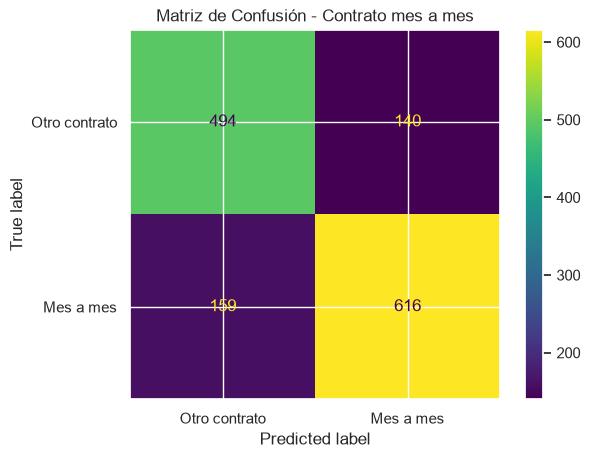

In [ ]:
# Nuevo target: ¿el cliente tiene contrato mes a mes?
y_contrato = (df["Contract"] == "Month-to-month").astype(int)
X_contrato = df.drop(columns=["Contract", "Churn"])

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_contrato, y_contrato, test_size=0.2, stratify=y_contrato, random_state=7
)

categoricas_c = X_train_c.select_dtypes(include="object").columns.tolist()
numericas_c   = X_train_c.select_dtypes(include=np.number).columns.tolist()

modelo_contrato = Pipeline([
    ("preprocesamiento", ColumnTransformer([
        ("categoricas", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categoricas_c),
        ("numericas", "passthrough", numericas_c)])),
    ("modelo", DecisionTreeClassifier(random_state=7))
])

modelo_contrato.fit(X_train_c, y_train_c)
y_pred_c = modelo_contrato.predict(X_test_c)

print(f"Clientes con contrato mes a mes: {y_contrato.mean():.2%}")
print(f"Accuracy de un modelo naive:     {max(y_test_c.mean(), 1 - y_test_c.mean()):.4f}\n")
print(f"Accuracy:  {accuracy_score(y_test_c, y_pred_c):.4f}")
print(f"Precision: {precision_score(y_test_c, y_pred_c):.4f}")
print(f"Recall:    {recall_score(y_test_c, y_pred_c):.4f}")
print(f"F1-Score:  {f1_score(y_test_c, y_pred_c):.4f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_c, y_pred_c),
    display_labels=["Otro contrato", "Mes a mes"]
).plot()
plt.title("Matriz de Confusión - Contrato mes a mes")
plt.show()

### Conclusión de la Parte II

Con el nuevo target el árbol out-of-the-box alcanza un Accuracy de 78,78% y un F1-Score de 80,47%, contra un 55,00% que sacaría un modelo naive que siempre predijera la clase mayoritaria. La matriz de confusión muestra 494 verdaderos negativos, 140 falsos positivos, 159 falsos negativos y 616 verdaderos positivos.

Este sí es un resultado interpretable. El modelo supera al naive por casi 24 puntos, pero está lejos del 98% del primer intento, que es exactamente lo que uno espera de un problema predictivo real: hay señal, y también hay incertidumbre. La variable que más usa el árbol es `tenure`, lo cual tiene sentido, porque los clientes de contratos largos llevan más tiempo en la empresa.

Comparando los tres problemas que trabajamos: `Churn` resultó el más difícil (F1 63,82%), el tipo de contrato quedó en un punto intermedio (F1 80,47%), y los cargos mensuales altos daban 98,06% pero por un motivo falso.

Lo que nos llevamos de esta parte es que un número muy alto de entrada no es una buena noticia, es una señal de alerta. Si no hubiéramos revisado por qué el primer modelo acertaba tanto, habríamos entregado como hallazgo lo que en realidad era el modelo descubriendo una división entre dos columnas.

# Conclusiones

## Síntesis de los hallazgos

Para Churn (Parte I), el primer árbol que entrenamos, sin restricciones, llegó a profundidad 24 y memorizó el 99,84% del train, pero en Cross-Validation cayó a 72,54% de Accuracy, por debajo del modelo naive (73,46%). El problema no era el algoritmo sino dejarlo crecer sin control de complejidad.

Usamos `GridSearchCV` sobre la misma Cross-Validation de 5 folds para buscar `max_depth` y `min_samples_leaf`, optimizando F1 en lugar de Accuracy por el desbalance de clases. El árbol resultante (`max_depth=5`, `min_samples_leaf=50`) alcanzó un Accuracy de 80,77% en test, con Precision 63,73%, Recall 63,90% y F1 63,82%.

Sobre el balanceo de clases llegamos a una conclusión que no esperábamos. En la partición principal el oversampling sube el Recall de 63,90% a 80,75% pero baja la Precision de 63,73% a 52,61%, y el F1 queda igual (0,6371 contra 0,6382). Al repetir sobre 5 particiones el F1 sí mejora (0,5936 a 0,6172), pero el Average Precision, que no depende del umbral, queda por debajo del modelo base (0,6120 contra 0,6163) y le gana en solo 1 de 5. No aprende a distinguir mejor a los clientes, sino que simplemente predice Churn más seguido. Lo comprobamos moviendo el umbral del modelo base de 0,50 a 0,27, elegido con Cross-Validation sobre train, y obtuvimos un F1 de 0,6456, mejor que el del oversampling, sin duplicar una sola fila.

En el análisis de negocio, un Falso Negativo cuesta unas 8 veces más que un Falso Positivo, pero eso no alcanza para elegir un modelo. Con una retención del 30% el modelo Base sale más barato (\$313.258 contra \$317.948) y recién a partir de una retención del 38,3% conviene el de Oversampling. Además, para que la campaña tenga sentido frente a no hacer nada, el descuento tiene que retener a más del 19,2% de los contactados. Ese número, qué tan efectivo es el descuento, importa más que la elección entre modelos, y habría que estimarlo con una prueba piloto antes de lanzar nada. También vimos que el umbral que minimiza el costo (0,42) no es el que maximiza el F1 (0,27).

En la Parte II el primer target que elegimos, cargos mensuales altos o bajos, dio un F1 de 98,06% que resultó ser falso: `TotalCharges` dividido `tenure` reconstruye `MonthlyCharges` con una diferencia promedio de \$1,75, y una regla de una línea sin entrenar nada acierta el 97,59%. Al sacar los servicios contratados el Accuracy se cae a 63,17%, confirmando que el target se podía calcular a partir de las predictoras. Lo reemplazamos por predecir si el cliente tiene contrato mes a mes, donde el mismo modelo simple llega a un F1 de 80,47% contra un naive de 55,00%. Es un resultado más bajo pero real.

## Posibles mejoras futuras

- Probar Random Forest o Gradient Boosting, más robustos al overfitting que un único árbol, y compararlos con Average Precision además de F1.
- Sumar una regresión logística con las variables escaladas: sería el caso donde el escalado que descartamos en 2.7 sí hace falta, y permitiría comparar un modelo lineal contra los árboles.
- Reemplazar los supuestos económicos (valor del cliente, porcentaje de retención) por datos reales o una prueba piloto A/B, ya que son los que más influyen en la decisión final.
- Elegir el umbral directamente por costo esperado en lugar de por F1, ahora que tenemos el modelo de costos armado.